# 04 · Selected random forests: results tables and figures

Picks the best RF for each issue date, rebuilds its validation predictions, and makes the tables and figures used in
the report and slides. **No grid search here** — it reads notebooks 02 and 03.

| Step | Output in `results/rf/04_selected_models/` | Used in the report |
|---|---|---|
| 1. Pick the best model per issue date (lower MAE of large/small; Mar15-small also compares the refined grid) | `selected_models.csv` | |
| 2. Rebuild out-of-fold (OOF) predictions; check they reproduce the saved CV scores | `{date}_{sample}_oof_predictions.csv`, `reproduction_check.csv` | |
| 3. CV scores of the selected models (mean of 5 folds) | `selected_models_cv_summary.csv` | Table "Best random forest for each issue date" |
| 4. 15 March tuning figure (initial + refined grids) | `rf_tuning_mar15_small.png`, `mar15_small_combined_grid.csv` | Figure "Random forest refined grid" |
| 5. Errors by region (15 March) | `rf_mar15_predicted_vs_actual_by_region.png`, `mar15_region_mae.csv`, `mar15_region_fold_mae.csv` | Figure "Predicted against actual", Table "MAE by region and by year" |
| 6. Errors by year (15 March) | `rf_mar15_predicted_vs_actual_by_year.png`, `mar15_year_mae.csv` | same table |
| 7. Errors by station, Hokkaido detail | `mar15_station_mae.csv`, `mar15_hokkaido_year_mae.csv` | |

Run notebooks 02 and 03 first (their results are in the repo). Runtime: about 1 minute.

All scores are cross-validation scores on 2005–2014; the same folds chose the hyperparameters, so they are not a test score.
Region and year MAEs pool all validation records, so they differ slightly from the fold-mean MAE in step 3.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

from rf_common import *

OUTPUT_OVERRIDE = None   # None = results/rf/04_selected_models
OUT = output_dir('04_selected_models', OUTPUT_OVERRIDE)
GRID_DIR = RF_RESULTS / '02_anomaly_grid'
REFINED_DIR = RF_RESULTS / '03_mar15_refined'

DPI = 300
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 12,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=DPI, bbox_inches='tight', facecolor='white')

print('Results go to:', OUT)

Results go to: /home/claude/sakura_analytics/results/rf/04_selected_models


## 1. Pick the best model for each issue date

In [2]:
best_models = read_csv(GRID_DIR / 'best_models.csv')
refined_grid = read_csv(REFINED_DIR / 'mar15_small_refined_grid_search_all_candidates.csv')

selected_rows = []
for date in ['feb1', 'mar1', 'mar15']:
    rows = best_models.loc[best_models['dataset'].str.lower().str.startswith(date + '-')]
    winner = rows.loc[rows['valid_MAE'].idxmin()]
    sample = winner['dataset'].split('-')[1]
    row = {'date': date, 'sample': sample, 'search': '02 anomaly grid',
           'candidate_id': int(winner['best_candidate_id']),
           'saved_valid_MAE': winner['valid_MAE'],
           'saved_valid_hit_rate_3d': winner['valid_hit_rate_3d'],
           **parse_params(winner)}

    # 15 March, small sample: notebook 03 searched more finely around the same model.
    if date == 'mar15' and sample == 'small':
        refined = best_row(refined_grid)
        if refined['valid_MAE'] < winner['valid_MAE']:
            row.update({'search': '03 refined grid', 'candidate_id': int(refined['candidate_id']),
                        'saved_valid_MAE': refined['valid_MAE'],
                        'saved_valid_hit_rate_3d': refined['valid_hit_rate_3d'],
                        **parse_params(refined)})
        print(f"Mar15-small: grid 02 MAE {winner['valid_MAE']:.5f}, "
              f"refined 03 MAE {refined['valid_MAE']:.5f} -> {row['search']}")
    selected_rows.append(row)

selected = pd.DataFrame(selected_rows)
save_csv(selected, OUT / 'selected_models.csv')
display(selected)

Mar15-small: grid 02 MAE 3.05780, refined 03 MAE 3.04647 -> 03 refined grid


,date,sample,search,candidate_id,saved_valid_MAE,saved_valid_hit_rate_3d,n_estimators,max_depth,min_samples_leaf,max_features
0,feb1,large,02 anomaly grid,4,3.784608,0.474229,200,5,30,sqrt
1,mar1,large,02 anomaly grid,17,3.555300,0.512052,500,5,30,1.0
2,mar15,small,03 refined grid,4,3.046475,0.585417,500,8,10,0.7


## 2. Rebuild the out-of-fold predictions

Each selected model is refitted on the five CV folds (25 fits in total) to get its validation predictions.
The rebuilt fold-mean scores must match the saved grid-search scores; otherwise the notebook stops.

In [3]:
oof = {}
check_rows = []

for row in selected_rows:
    date, sample = row['date'], row['sample']
    data = load_sample(date, sample, development_only=True)
    features = feature_columns(data)
    params = {k: row[k] for k in PARAM_COLUMNS}

    parts, fold_scores = [], []
    for fold, train, valid in cv_folds(data):
        check_folds(train, valid, f'{date}-{sample} fold {fold}')
        model, reference = fit_anomaly_rf(train, features, params)
        part = valid[['station_id', 'location', 'region', 'bloom_year']].copy()
        part['fold'] = fold
        part['actual_doy'] = valid[TARGET].to_numpy()
        part['predicted_doy'] = predict_doy(model, reference, valid, features)
        part['station_reference_doy'] = reference_values(reference, valid)
        part['error_days'] = part['predicted_doy'] - part['actual_doy']
        parts.append(part)
        fold_scores.append(evaluate(part['actual_doy'], part['predicted_doy']))

    predictions = pd.concat(parts, ignore_index=True)
    save_csv(predictions, OUT / f'{date}_{sample}_oof_predictions.csv')
    oof[date] = predictions

    rebuilt = pd.DataFrame(fold_scores).mean()
    check_rows.append({
        'model': f'{date}-{sample}', 'search': row['search'],
        'saved_valid_MAE': row['saved_valid_MAE'], 'rebuilt_valid_MAE': rebuilt['MAE'],
        'saved_hit_rate_3d': row['saved_valid_hit_rate_3d'],
        'rebuilt_hit_rate_3d': rebuilt['hit_rate_3d'],
    })
    print(f'{date}-{sample}: rebuilt MAE {rebuilt["MAE"]:.5f} (saved {row["saved_valid_MAE"]:.5f})')

check = pd.DataFrame(check_rows)
save_csv(check, OUT / 'reproduction_check.csv')
display(check)

if ((check['rebuilt_valid_MAE'] - check['saved_valid_MAE']).abs().max() > 0.01
        or (check['rebuilt_hit_rate_3d'] - check['saved_hit_rate_3d']).abs().max() > 0.01):
    raise RuntimeError('Rebuilt scores differ from the saved grid search - check data, features and versions.')

feb1-large: rebuilt MAE 3.78461 (saved 3.78461)


mar1-large: rebuilt MAE 3.55530 (saved 3.55530)


mar15-small: rebuilt MAE 3.04647 (saved 3.04647)


,model,search,saved_valid_MAE,rebuilt_valid_MAE,saved_hit_rate_3d,rebuilt_hit_rate_3d
0,feb1-large,02 anomaly grid,3.784608,3.784608,0.474229,0.474229
1,mar1-large,02 anomaly grid,3.555300,3.555300,0.512052,0.512052
2,mar15-small,03 refined grid,3.046475,3.046475,0.585417,0.585417


## 3. CV scores of the selected models (mean of the five folds)

In [4]:
DATE_LABELS = {'feb1': '1 Feb', 'mar1': '1 Mar', 'mar15': '15 Mar'}

summary_rows = []
for row in selected_rows:
    predictions = oof[row['date']]
    fold_metrics = pd.DataFrame([
        evaluate(part['actual_doy'], part['predicted_doy'])
        for _, part in predictions.groupby('fold')
    ])
    summary_rows.append({
        'issue_date': DATE_LABELS[row['date']],
        'sample': row['sample'],
        'search': row['search'],
        'n_estimators': row['n_estimators'],
        'max_depth': row['max_depth'],
        'min_samples_leaf': row['min_samples_leaf'],
        'max_features': row['max_features'],
        'validation_stations': predictions['station_id'].nunique(),
        'validation_records': len(predictions),
        'MAE': fold_metrics['MAE'].mean(),
        'RMSE': fold_metrics['RMSE'].mean(),
        'R2': fold_metrics['R2'].mean(),
        'hit_rate_3d_pct': 100 * fold_metrics['hit_rate_3d'].mean(),
    })

cv_summary = pd.DataFrame(summary_rows)
save_csv(cv_summary, OUT / 'selected_models_cv_summary.csv')
display(cv_summary.round(3))

,issue_date,sample,search,n_estimators,max_depth,min_samples_leaf,max_features,validation_stations,validation_records,MAE,RMSE,R2,hit_rate_3d_pct
0,1 Feb,large,02 anomaly grid,200,5,30,sqrt,76,575,3.785,4.552,0.815,47.423
1,1 Mar,large,02 anomaly grid,500,5,30,1.0,76,575,3.555,4.264,0.831,51.205
2,15 Mar,small,03 refined grid,500,8,10,0.7,48,480,3.046,3.691,0.881,58.542


## 4. 15 March tuning figure: initial and refined grids together

Each panel varies one hyperparameter; each grey line holds the other three fixed. The pink line passes through the
overall best candidate (star). Settings that appear in both grids must give the same MAE (checked below).

Settings in both grids:


,n_estimators,max_depth,min_samples_leaf,max_features,valid_MAE_initial,valid_MAE_refined,difference_days
0,500,10,10,0.7,3.057797,3.057797,0.0


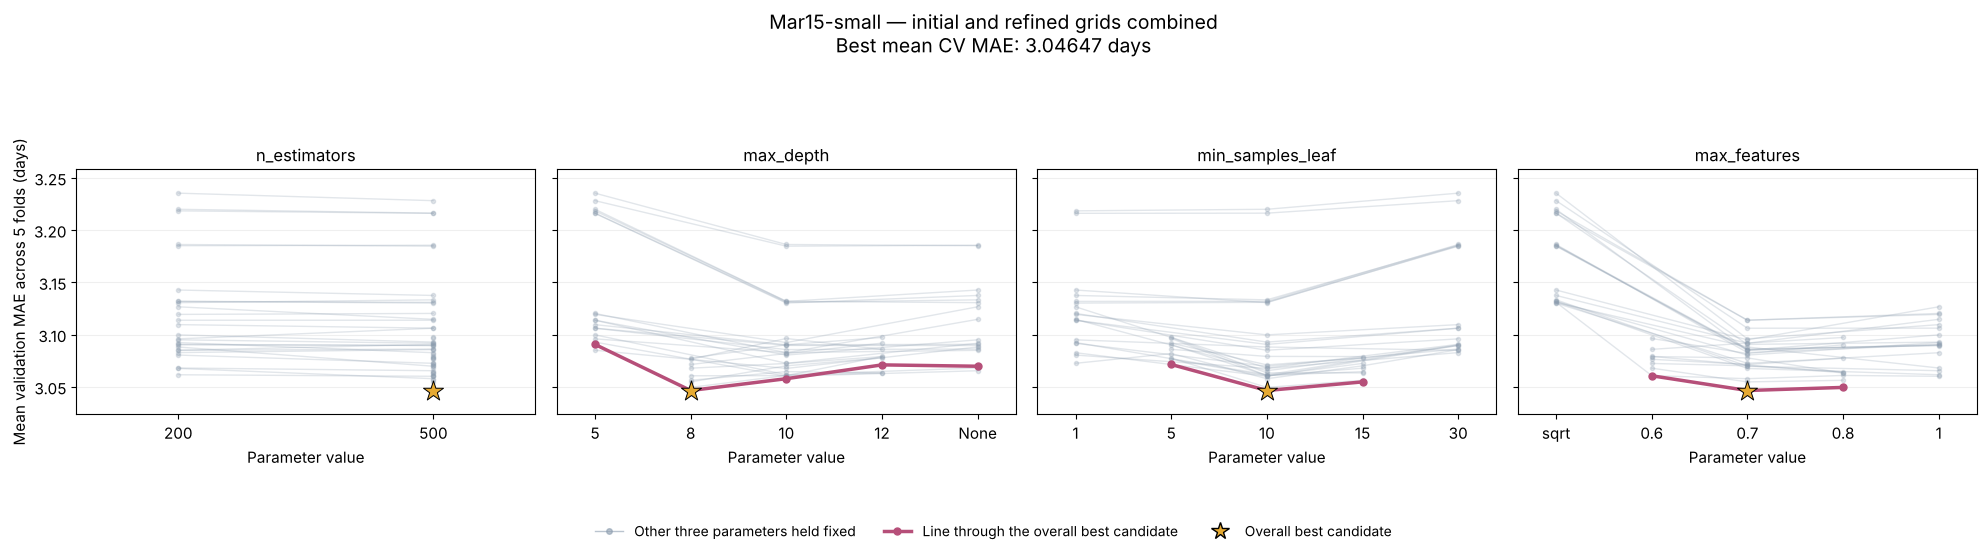

In [5]:
PARAMS = ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']
DISPLAY_ORDER = {
    'n_estimators': ['200', '500'],
    'max_depth': ['5', '8', '10', '12', 'None'],
    'min_samples_leaf': ['1', '5', '10', '15', '30'],
    'max_features': ['sqrt', '0.6', '0.7', '0.8', '1'],
}

def label_value(value, parameter):
    if pd.isna(value) or str(value).strip().lower() in ('none', 'nan'):
        return 'None'
    if parameter == 'max_features':
        try:
            return f'{float(value):g}'
        except (TypeError, ValueError):
            return str(value).strip()
    return str(int(float(value)))

def load_grid(path, search):
    frame = read_csv(path)
    for parameter in PARAMS:
        frame[parameter] = frame[parameter].map(lambda v: label_value(v, parameter))
    if frame.duplicated(PARAMS).any():
        raise ValueError(f'{search}: duplicated settings')
    frame['search'] = search
    return frame

initial = load_grid(GRID_DIR / 'mar15_small_grid_search_all_candidates.csv', 'Initial')
refined = load_grid(REFINED_DIR / 'mar15_small_refined_grid_search_all_candidates.csv', 'Refined')

common = initial[PARAMS + ['valid_MAE']].merge(
    refined[PARAMS + ['valid_MAE']], on=PARAMS,
    suffixes=('_initial', '_refined'), validate='one_to_one',
)
common['difference_days'] = common['valid_MAE_refined'] - common['valid_MAE_initial']
print('Settings in both grids:')
display(common.round(6))
if common['difference_days'].abs().max() > 0.01:
    raise ValueError('The same settings give different MAEs in the two grids.')

# Union of both grids; the refined run wins for settings that appear twice.
combined = (
    pd.concat([initial, refined], ignore_index=True)
    .drop_duplicates(subset=PARAMS, keep='last')
    .reset_index(drop=True)
)
save_csv(combined, OUT / 'mar15_small_combined_grid.csv')
global_best = combined.loc[combined['valid_MAE'].idxmin()]

minimum, maximum = combined['valid_MAE'].min(), combined['valid_MAE'].max()
padding = max((maximum - minimum) * 0.12, 0.003)

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), sharey=True)
for ax, parameter in zip(axes, PARAMS):
    categories = [v for v in DISPLAY_ORDER[parameter] if v in set(combined[parameter])]
    position = {value: i for i, value in enumerate(categories)}
    others = [p for p in PARAMS if p != parameter]
    best_others = tuple(global_best[p] for p in others)
    highlighted = None

    for settings, group in combined.groupby(others, sort=False):
        group = group.assign(x=group[parameter].map(position)).sort_values('x')
        ax.plot(group['x'], group['valid_MAE'], color='#8C9DAF', alpha=0.25,
                linewidth=1, marker='o', markersize=3, zorder=1)
        if tuple(settings) == best_others:
            highlighted = group

    if highlighted is not None:
        ax.plot(highlighted['x'], highlighted['valid_MAE'], color='#B64F79',
                linewidth=2.5, marker='o', markersize=5, zorder=4)
    ax.scatter(position[global_best[parameter]], global_best['valid_MAE'], marker='*', s=230,
               color='#E6AA32', edgecolors='black', linewidths=0.7, zorder=5)

    ax.set_title(parameter)
    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories)
    ax.set_xlim(-0.4, len(categories) - 0.6)
    ax.set_ylim(minimum - padding, maximum + padding)
    ax.set_xlabel('Parameter value')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel('Mean validation MAE across 5 folds (days)')
fig.legend(handles=[
    Line2D([], [], color='#8C9DAF', marker='o', markersize=4, linewidth=1, alpha=0.6,
           label='Other three parameters held fixed'),
    Line2D([], [], color='#B64F79', marker='o', markersize=5, linewidth=2.5,
           label='Line through the overall best candidate'),
    Line2D([], [], linestyle='None', marker='*', markersize=13, markerfacecolor='#E6AA32',
           markeredgecolor='black', label='Overall best candidate'),
], loc='lower center', ncol=3, frameon=False, fontsize=10)
fig.suptitle('Mar15-small — initial and refined grids combined\n'
             f"Best mean CV MAE: {global_best['valid_MAE']:.5f} days", fontsize=14)
fig.tight_layout(rect=[0, 0.12, 1, 0.88])
save_figure(fig, 'rf_tuning_mar15_small')
plt.show()

## 5. 15 March: errors by region

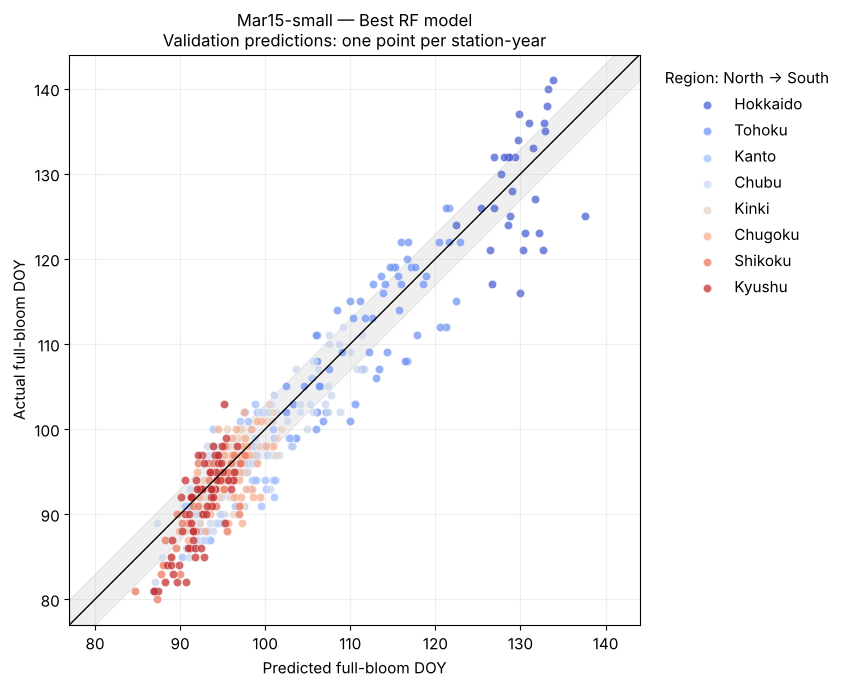

MAE by region (pooled validation records; signed error > 0 = predicted too late)


,region,stations,records,MAE_days,mean_signed_error_days,hit_rate_3d_pct
0,Hokkaido,3,30,5.321,0.965,26.667
1,Tohoku,6,60,3.813,0.713,41.667
2,Kanto,7,70,3.421,1.956,50.000
3,Chubu,9,90,2.754,1.219,61.111
4,Kinki,7,70,2.090,0.743,81.429
5,Chugoku,5,50,2.525,1.226,66.000
6,Shikoku,4,40,2.399,1.509,70.000
7,Kyushu,7,70,3.115,1.433,57.143
8,Overall,48,480,3.046,1.234,58.542


MAE by region and fold (fold k validates 2005+2k-2 and 2005+2k-1)


,region,fold1,fold2,fold3,fold4,fold5,all_folds
0,Hokkaido,4.557,6.352,4.351,2.699,8.645,5.321
1,Tohoku,1.959,4.234,5.166,2.604,5.105,3.813
2,Kanto,3.024,3.966,1.205,3.346,5.565,3.421
3,Chubu,2.023,3.135,2.705,2.174,3.731,2.754
4,Kinki,0.996,1.971,1.192,2.255,4.037,2.090
5,Chugoku,1.359,1.887,1.973,2.261,5.144,2.525
6,Shikoku,2.045,1.734,2.444,1.440,4.334,2.399
7,Kyushu,2.128,2.215,3.864,2.008,5.360,3.115


In [6]:
mar15 = oof['mar15'].copy()
mar15['area'] = mar15['region'].map(canonical_region)
mar15['abs_error'] = mar15['error_days'].abs()
mar15['within_3_days'] = mar15['abs_error'] <= 3
regions = [r for r in REGION_ORDER if r in set(mar15['area'])]

# Predicted against actual, coloured north (blue) to south (red)
cmap = plt.get_cmap('coolwarm')
region_colors = {r: cmap(p) for r, p in zip(regions, np.linspace(0.05, 0.95, len(regions)))}
lower = np.floor(mar15[['actual_doy', 'predicted_doy']].min().min()) - 3
upper = np.ceil(mar15[['actual_doy', 'predicted_doy']].max().max()) + 3

fig, ax = plt.subplots(figsize=(9, 7))
ax.fill_between([lower, upper], [lower - 3, upper - 3], [lower + 3, upper + 3],
                color='gray', alpha=0.12)
ax.plot([lower, upper], [lower, upper], color='black', linewidth=1)
for region in regions:
    part = mar15.loc[mar15['area'] == region]
    ax.scatter(part['predicted_doy'], part['actual_doy'], color=region_colors[region],
               label=region, s=35, alpha=0.75, edgecolors='white', linewidths=0.3)
ax.set(xlabel='Predicted full-bloom DOY', ylabel='Actual full-bloom DOY',
       xlim=(lower, upper), ylim=(lower, upper),
       title='Mar15-small — Best RF model\nValidation predictions: one point per station-year')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=0.2)
ax.legend(title='Region: North → South', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig.tight_layout()
save_figure(fig, 'rf_mar15_predicted_vs_actual_by_region')
plt.show()

# MAE by region, pooling all validation records
region_mae = (
    mar15.groupby('area')
    .agg(stations=('station_id', 'nunique'), records=('abs_error', 'size'),
         MAE_days=('abs_error', 'mean'), mean_signed_error_days=('error_days', 'mean'),
         hit_rate_3d_pct=('within_3_days', 'mean'))
    .reindex(regions).rename_axis('region').reset_index()
)
region_mae['hit_rate_3d_pct'] *= 100
overall = {'region': 'Overall', 'stations': mar15['station_id'].nunique(), 'records': len(mar15),
           'MAE_days': mar15['abs_error'].mean(),
           'mean_signed_error_days': mar15['error_days'].mean(),
           'hit_rate_3d_pct': 100 * mar15['within_3_days'].mean()}
region_mae = pd.concat([region_mae, pd.DataFrame([overall])], ignore_index=True)
save_csv(region_mae, OUT / 'mar15_region_mae.csv')
print('MAE by region (pooled validation records; signed error > 0 = predicted too late)')
display(region_mae.round(3))

# Region × fold: is one bad region driven by one bad fold?
region_fold = (
    mar15.pivot_table(index='area', columns='fold', values='abs_error', aggfunc='mean')
    .reindex(regions)
)
region_fold.columns = [f'fold{k}' for k in region_fold.columns]
region_fold['all_folds'] = mar15.groupby('area')['abs_error'].mean().reindex(regions)
region_fold = region_fold.rename_axis('region').reset_index()
save_csv(region_fold, OUT / 'mar15_region_fold_mae.csv')
print('MAE by region and fold (fold k validates 2005+2k-2 and 2005+2k-1)')
display(region_fold.round(3))

## 6. 15 March: errors by year

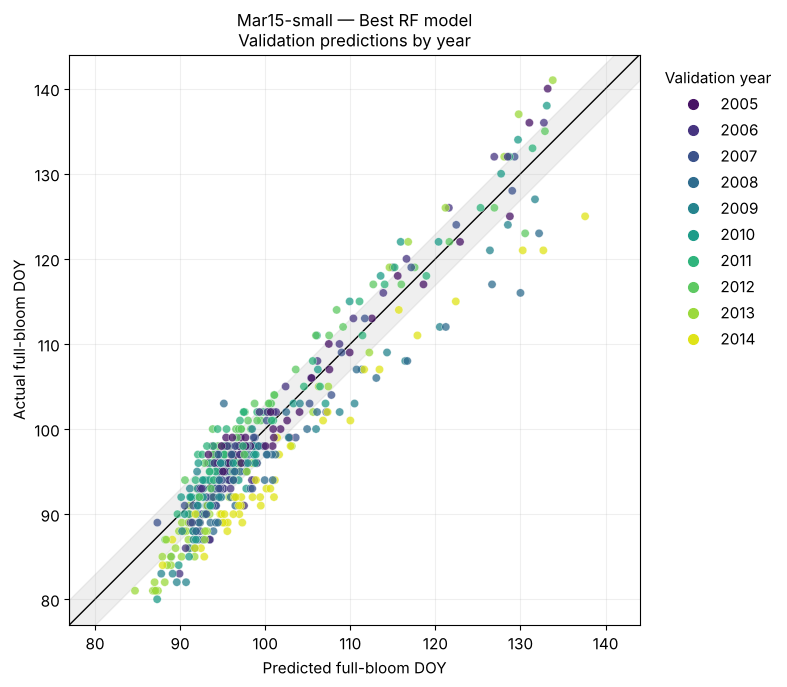

,year,fold,stations,records,MAE_days,mean_signed_error_days,hit_rate_3d_pct
0,2005,1,48,48,1.846,-0.631,83.333
1,2006,1,48,48,2.389,0.581,68.750
2,2007,2,48,48,2.074,1.264,75.000
3,2008,2,48,48,4.014,3.409,41.667
4,2009,3,48,48,3.054,2.513,62.500
5,2010,3,48,48,2.440,0.489,66.667
6,2011,4,48,48,2.216,-2.085,75.000
7,2012,4,48,48,2.518,-1.749,64.583
8,2013,5,48,48,3.902,2.539,35.417
9,2014,5,48,48,6.012,6.012,12.500


In [7]:
years = sorted(mar15['bloom_year'].unique())
year_colors = {y: plt.get_cmap('viridis')(p) for y, p in zip(years, np.linspace(0.05, 0.95, len(years)))}

fig, ax = plt.subplots(figsize=(10, 7))
ax.fill_between([lower, upper], [lower - 3, upper - 3], [lower + 3, upper + 3],
                color='gray', alpha=0.12, zorder=0)
ax.plot([lower, upper], [lower, upper], color='black', linewidth=1, zorder=1)
shuffled = mar15.sample(frac=1, random_state=42)   # so later years do not hide earlier ones
ax.scatter(shuffled['predicted_doy'], shuffled['actual_doy'],
           c=[year_colors[y] for y in shuffled['bloom_year']],
           s=35, alpha=0.75, edgecolors='white', linewidths=0.3, zorder=2)
ax.legend(handles=[Line2D([], [], marker='o', linestyle='None', color=year_colors[y],
                          label=str(y), markersize=7) for y in years],
          title='Validation year', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
ax.set(xlabel='Predicted full-bloom DOY', ylabel='Actual full-bloom DOY',
       xlim=(lower, upper), ylim=(lower, upper),
       title='Mar15-small — Best RF model\nValidation predictions by year')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=0.2)
fig.tight_layout()
save_figure(fig, 'rf_mar15_predicted_vs_actual_by_year')
plt.show()

year_mae = (
    mar15.groupby('bloom_year')
    .agg(fold=('fold', 'first'), stations=('station_id', 'nunique'),
         records=('abs_error', 'size'), MAE_days=('abs_error', 'mean'),
         mean_signed_error_days=('error_days', 'mean'),
         hit_rate_3d_pct=('within_3_days', 'mean'))
    .rename_axis('year').reset_index()
)
year_mae['hit_rate_3d_pct'] *= 100
save_csv(year_mae, OUT / 'mar15_year_mae.csv')
display(year_mae.round(3))

## 7. 15 March: errors by station, with Hokkaido in detail

Hokkaido has only 3 stations in the small sample (30 validation records), so its regional MAE rests on few points.

In [8]:
station_mae = (
    mar15.groupby(['station_id', 'location', 'area'])
    .agg(records=('abs_error', 'size'), MAE_days=('abs_error', 'mean'),
         mean_signed_error_days=('error_days', 'mean'),
         hit_rate_3d_pct=('within_3_days', 'mean'))
    .reset_index().rename(columns={'area': 'region'})
    .sort_values('MAE_days', ascending=False).reset_index(drop=True)
)
station_mae['hit_rate_3d_pct'] *= 100
save_csv(station_mae, OUT / 'mar15_station_mae.csv')

print('Hokkaido stations')
display(station_mae.loc[station_mae['region'] == 'Hokkaido'].round(3))
print('Ten stations with the largest MAE')
display(station_mae.head(10).round(3))

hokkaido_year = (
    mar15.loc[mar15['area'] == 'Hokkaido']
    .groupby(['bloom_year', 'fold'])
    .agg(records=('abs_error', 'size'), MAE_days=('abs_error', 'mean'),
         mean_signed_error_days=('error_days', 'mean'))
    .reset_index()
)
save_csv(hokkaido_year, OUT / 'mar15_hokkaido_year_mae.csv')
print('Hokkaido by year (signed error > 0 = predicted too late)')
display(hokkaido_year.round(3))

Hokkaido stations


,station_id,location,region,records,MAE_days,mean_signed_error_days,hit_rate_3d_pct
0,412,Sapporo,Hokkaido,10,6.204,1.553,10.0
1,423,Muroran,Hokkaido,10,5.504,-0.207,30.0
3,430,Hakodate,Hokkaido,10,4.254,1.550,40.0


Ten stations with the largest MAE


,station_id,location,region,records,MAE_days,mean_signed_error_days,hit_rate_3d_pct
0,412,Sapporo,Hokkaido,10,6.204,1.553,10.0
1,423,Muroran,Hokkaido,10,5.504,-0.207,30.0
2,584,Morioka,Tohoku,10,4.954,0.175,20.0
3,430,Hakodate,Hokkaido,10,4.254,1.550,40.0
4,575,Aomori,Tohoku,10,4.003,1.392,50.0
5,590,Sendai,Tohoku,10,3.991,1.513,40.0
6,662,Tokyo,Kanto,10,3.891,2.721,40.0
7,629,Mito,Kanto,10,3.820,2.915,50.0
8,819,Kumamoto,Kyushu,10,3.801,1.629,40.0
9,588,Yamagata,Tohoku,10,3.791,0.509,30.0


Hokkaido by year (signed error > 0 = predicted too late)


,bloom_year,fold,records,MAE_days,mean_signed_error_days
0,2005,1,3,5.171,-2.667
1,2006,1,3,3.944,-3.944
2,2007,2,3,1.757,-1.070
3,2008,2,3,10.947,10.947
4,2009,3,3,4.879,4.879
5,2010,3,3,3.824,-3.824
6,2011,4,3,1.862,-1.862
7,2012,4,3,3.535,2.119
8,2013,5,3,6.108,-6.108
9,2014,5,3,11.183,11.183
